# Hamiltonian dynamics: explicit circuits and independent checks

Open chain $H=\sum_{i=0}^{1}Z_iZ_{i+1}+0.7\sum_{i=0}^{2}X_i$, three qubits, $t=1$, $\hbar=1$, starting in $|000\rangle$. The observable is $Z(q_0)$. Product formulas implement dynamics. Taylor LCU implements postselected approximate dynamics. QSP implements a cosine filter; full complex QSP dynamics remains planned.

The source modules and frozen phases are original MIT code built on Qiskit 2.6.2 (Apache-2.0), NumPy and SciPy 1.18.1 (BSD-3-Clause). The chapter provides primary algorithm references. Dense matrices below are bounded classical checks, never circuit gates.

In [1]:
from pathlib import Path
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from qiskit.quantum_info import Operator, Statevector

root = Path.cwd()
if not (root / "src/openquantum/hamiltonian_simulation.py").exists() and (root.parent / "src/openquantum/hamiltonian_simulation.py").exists():
    root = root.parent
if (root / "src/openquantum/hamiltonian_simulation.py").exists():
    sys.path.insert(0, str(root / "src"))
    from openquantum import hamiltonian_simulation as hs
    from openquantum.simulation import lcu, qsp
else:
    # Save the three downloaded Python modules beside this notebook.
    sys.path.insert(0, str(root))
    import hamiltonian_simulation as hs
    import lcu
    import qsp

terms = hs.spin_terms(3)
H = hs.dense_hamiltonian(3)
exact = hs.exact_evolution(3, 1)
initial = np.eye(8, dtype=complex)[:, 0]
Z0 = hs.pauli_matrix("IIZ")
exact_z = float(np.vdot(exact @ initial, Z0 @ exact @ initial).real)
print(f"Exact Z(q0) = {exact_z:.12f}")

Exact Z(q0) = 0.404255857287


## A single explicit symmetric step

The displayed circuit uses one step to expose CX–RZ–CX and RX construction. The accuracy run uses 32 steps. The rotation convention is $R_P(\theta)=e^{-i\theta P/2}$. The zero basis state needs no preparation gates; a physical run still needs initialization.

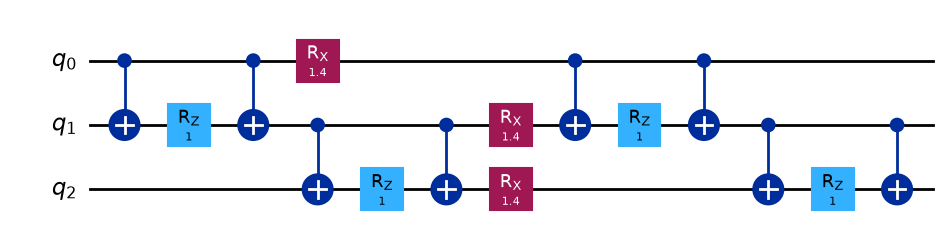

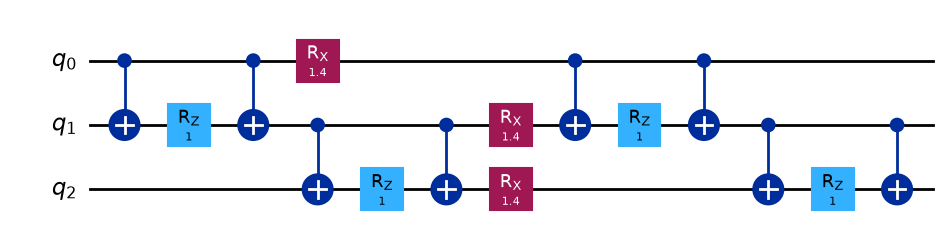

In [2]:
hs.product_formula_circuit(3, 1, 1, 2).draw(output="mpl", fold=30)

## States, operators and observables

We check the full operator spectral norm, state-vector norm, infidelity and observable bias separately. These two layer orderings give equal $Z(q_0)$ probabilities on this input: the initial ZZ layer contributes a global phase and the final ZZ layer commutes with the measured observable. Their states and operators differ.

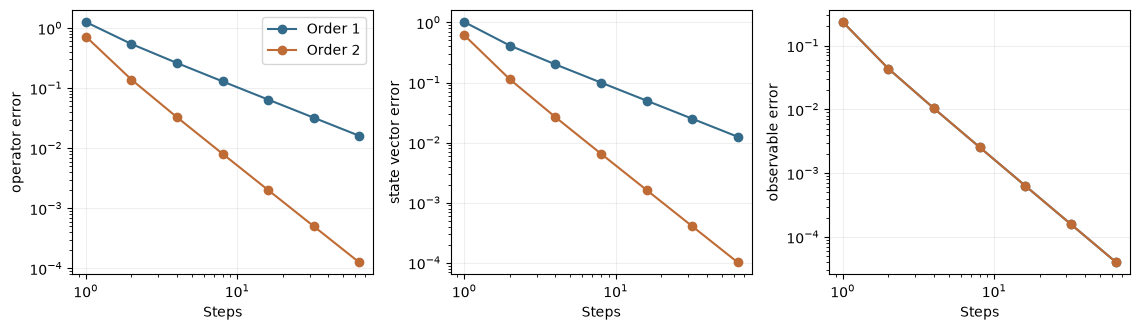

In [3]:
rows = [hs.compare_product_formula(3, 1, r, order) for order in (1, 2) for r in (1, 2, 4, 8, 16, 32, 64)]
convergence = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
for order, color in ((1, "#346b8a"), (2, "#be6b35")):
    group = convergence[convergence.order == order]
    for ax, key in zip(axes, ("operator_error", "state_vector_error", "observable_error")):
        ax.loglog(group.steps, group[key], "o-", color=color, label=f"Order {order}")
        ax.set(xlabel="Steps", ylabel=key.replace("_", " "))
        ax.grid(alpha=.2)
axes[0].legend()
fig.tight_layout()
plt.show()

In [4]:
display(convergence.loc[convergence.steps.isin([8, 16, 32]), ["order", "steps", "operator_error", "state_vector_error", "state_infidelity", "observable_error"]].reset_index(drop=True))
assert hs.compare_product_formula(steps=32, order=2)["operator_error"] < .005

,order,steps,operator_error,state_vector_error,state_infidelity,observable_error
0,1,8,0.129286,0.099653,5.890317e-03,0.002555
1,1,16,0.064400,0.049879,1.439509e-03,0.000637
2,1,32,0.032155,0.024968,3.561908e-04,0.000159
3,2,8,0.008075,0.006517,3.565094e-05,0.002555
4,2,16,0.002012,0.001623,2.208964e-06,0.000637
5,2,32,0.000503,0.000405,1.377627e-07,0.000159


## Logical measurements and a proposed budget

Arbitrary rotations remain unsynthesized. An observable-error proposal of 0.05 allocates 0.01 to evolution bias, 0.01 to coherent synthesis bias and 0.03 to independent sampling. Statistical failure and total physical failure are separately proposed at 0.005 each. Hoeffding requires 13,315 shots for a +/-1 observable. No physical estimate is claimed.

In [5]:
measured = hs.decompose(hs.product_formula_circuit(3, 1, 32, 2, measure=True))
counts = dict(measured.count_ops())
shots = hs.observable_shots()
rotation_count = sum(counts.get(g, 0) for g in ("rx", "ry", "rz"))
display(pd.DataFrame({"per shot": counts, "proposed all shots": {g: shots * c for g, c in counts.items()}}).fillna(0).astype(int))
print(f"Width {measured.num_qubits}; depth {measured.depth()}; rotations {rotation_count}; proposed shots {shots}")

,per shot,proposed all shots
cx,256,3408640
rz,128,1704320
rx,96,1278240
measure,3,39945
barrier,1,13315


Width 3; depth 417; rotations 224; proposed shots 13315


## Taylor LCU with actual access and postselection

The degree-4 polynomial is classically aggregated in the Pauli basis with a strict term cap. Its PREPARE uses controlled RY rotations, SELECT uses indexed Pauli operations and coefficient phases, and inverse PREPARE is present. This bounded preprocessing is not a scalable word-indexed Taylor oracle. All label outcomes must be zero. No amplitude-amplification circuit is implemented.

In [6]:
lcu_rows = []
for segments in (1, 2, 4, 8):
    access = lcu.build_taylor_lcu(terms, 1 / segments, 4)
    conditional, success, per_segment = lcu.postselected_lcu_evolution(access, initial, segments)
    value = float(np.vdot(conditional, Z0 @ conditional).real)
    lcu_rows.append({"segments": segments, "terms": len(access.terms), "normalization": access.normalization,
                     "conditional_state_error": float(np.linalg.norm(conditional - exact @ initial)),
                     "observable_error": abs(value - exact_z), "whole_attempt_success": success,
                     "attempts_for_one_measured_trial_99_percent": lcu.postselection_attempts(success, .01)})
display(pd.DataFrame(lcu_rows))

,segments,terms,normalization,conditional_state_error,observable_error,whole_attempt_success,attempts_for_one_measured_trial_99_percent
0,1,22,3.290337,0.971995,0.562003,0.054829,82
1,2,22,3.050865,0.039235,0.013270,0.010583,433
2,4,22,2.096897,0.003313,0.000377,0.002667,1725
3,8,22,1.538484,0.000225,0.000059,0.001015,4535


The state-error checks above describe the conditional state before final system readout. The exported attempt measures every system wire, so its retry bound obtains one accepted measured trial with at least 99% ideal acceptance probability. Estimating an observable needs many accepted measured trials and a new whole-workload retry/confidence budget. Circuit costs include access, uncomputation, label measurement/reset and final Z measurements; synthesis and physical faults remain pending.

## Genuine QSP cosine primitive

This is a real polynomial transform approximating $\cos(H)/2$, with a Hermitian block encoding of $H/4.1$, 14 block calls and frozen reproducible phases. It is a filter, so its accepted state is normalized differently from $e^{-iH}|000\rangle$. It is not a full complex evolution implementation.

In [7]:
from scipy.linalg import cosm
phase_check = qsp.verify_cosine_phases()
filter_circuit = qsp.build_real_qsp_filter(terms, qsp.COSINE_PHASES)
block = Operator(filter_circuit).data[:8, :8]
target = cosm(H) / 2
block_error = float(np.linalg.norm(block - target, 2))
assert block_error < 1e-7
filtered, filter_success = qsp.postselected_filter_state(filter_circuit, initial)
print(f"Cosine block spectral error: {block_error:.3e}")
print(f"Ideal filter postselection probability: {filter_success:.9f}")
checks = ["degree", "phase_fit_max_residual_10001_point_grid", "target_max_residual_10001_point_grid", "analytic_chebyshev_truncation_bound", "numerically_reconstructed_coefficient_l1_discrepancy"]
display(pd.DataFrame([{"check": key, "value": phase_check[key]} for key in checks]))

Cosine block spectral error: 3.396e-09
Ideal filter postselection probability: 0.178203377


,check,value
0,degree,1.400000e+01
1,phase_fit_max_residual_10001_point_grid,1.276756e-15
2,target_max_residual_10001_point_grid,3.676906e-09
3,analytic_chebyshev_truncation_bound,6.036819e-09
4,numerically_reconstructed_coefficient_l1_discr...,8.558458e-16


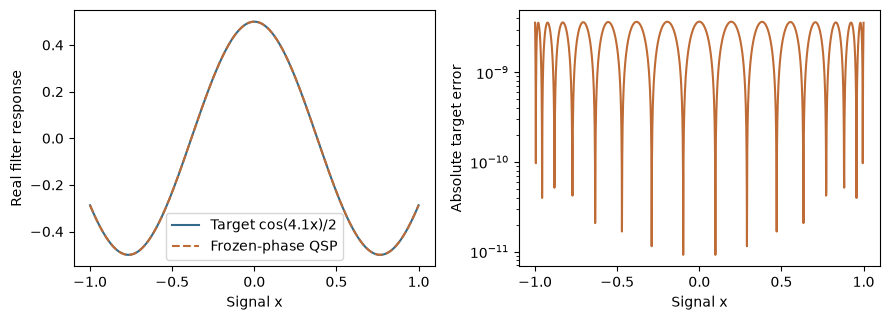

In [8]:
x = np.linspace(-1, 1, 2001)
response = qsp.qsp_real_response(x)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].plot(x, np.cos(4.1*x)/2, label="Target cos(4.1x)/2", color="#346b8a")
axes[0].plot(x, response, "--", label="Frozen-phase QSP", color="#be6b35")
axes[0].set(xlabel="Signal x", ylabel="Real filter response")
axes[0].legend()
axes[1].semilogy(x, np.maximum(abs(response-np.cos(4.1*x)/2), 1e-16), color="#be6b35")
axes[1].set(xlabel="Signal x", ylabel="Absolute target error")
fig.tight_layout()
plt.show()

## Optional live circuit exploration

When run with a live Python kernel, controls regenerate and check the actual product-formula circuit. Static builds omit widget objects. The saved figures above remain reproducible without a widget kernel.

In [9]:
if os.environ.get("OPENQUANTUM_STATIC_BUILD") != "1":
    import ipywidgets as widgets
    def explore(order=2, steps=8):
        result = hs.compare_product_formula(3, 1, steps, order)
        print(f"Operator error: {result['operator_error']:.6g}; Z bias: {result['observable_error']:.6g}")
        display(hs.product_formula_circuit(3, 1, steps, order).draw(output="mpl", fold=32))
    display(widgets.interactive(explore, order=widgets.Dropdown(options=[1, 2], value=2),
                                steps=widgets.IntSlider(min=1, max=16, value=8)))

## Limits and reproducibility

Product-formula generation supports at most 64 system qubits, 20,000 steps and 200,000 term exponentials; the dense validation path is limited to 8 qubits. Explicit Pauli LCU and QSP impose their own term/register and statevector caps. Phase fitting is numerical and separately reproducible. The polynomial truncation, phase residual, coherent synthesis, sampling and physical fault contracts are distinct. No GPU, formal proof, physical-resource advantage or full open-system/Gibbs implementation is claimed.